# Stage 05 — Machine Learning & Predictive Modeling
Georgia Income Analytics — Gender & Income Study.

**Target:** estimated real net monthly earnings of employees (band point estimate, 2025 GEL), Geostat LFS 2020–2025. Models learn log earnings; predictions back-transformed with smearing. Split 70/15/15 **by household**; hyper-parameters tuned with household-grouped CV on the training set; test set used once. **Model explanations are not causal evidence.**

In [1]:
import sys, json, numpy as np, pandas as pd, joblib
from IPython.display import Image, display
sys.path.insert(0,'../src')
import preprocessing as pp, model_evaluation as me, predict_income as pi
pd.set_option('display.width',200,'display.max_columns',30,'display.max_colwidth',60)
R='../reports/'

## 1. Data audit

In [2]:
df = pp.load_ml_frame()
part = pd.read_csv(str(pp.SPLIT_FILE).format(p=pp.MAIN_PERIOD)).part
print(json.dumps(pp.audit(df, part), indent=1, default=str))

{
 "rows": 81166,
 "households": 22200,
 "women": 40892,
 "men": 40274,
 "years": [
  2020,
  2021,
  2022,
  2023,
  2024,
  2025
 ],
 "target": "earnings_real_2025: band point estimate, real 2025 GEL, net, monthly (last worked month)",
 "target_distinct_values": 72,
 "missing": {
  "industry": 1,
  "sector": 12
 },
 "split_sizes": {
  "train": 56999,
  "validation": 12159,
  "test": 12008
 },
 "households_in_two_parts": 0,
 "leakage_columns_in_features": []
}


## 2. Model comparison (test set)

In [3]:
c = pd.read_csv(R+'ml_model_comparison.csv')
c[c.split=='test'][['experiment','model','MAE','RMSE','R2','MedAE','R2_log','selected_best']]

,experiment,model,MAE,RMSE,R2,MedAE,R2_log,selected_best
2,A_gender_included,Linear Regression,320.428805,460.156259,0.323367,229.155368,0.374402,False
5,A_gender_included,Ridge,319.947193,462.134576,0.317536,232.160266,0.359125,False
8,A_gender_included,Random Forest,273.759164,420.884142,0.433933,184.205218,0.532565,False
11,A_gender_included,Gradient Boosting,273.399252,413.255968,0.454266,185.554316,0.546131,False
14,A_gender_included,XGBoost,272.233438,413.057758,0.454789,185.749310,0.550030,True
17,B_gender_excluded,Linear Regression,325.472544,465.877662,0.306436,236.594055,0.361258,False
20,B_gender_excluded,Ridge,325.122338,465.959919,0.306191,237.190288,0.359699,False
23,B_gender_excluded,Random Forest,279.339525,425.813031,0.420597,189.716402,0.522546,False
26,B_gender_excluded,Gradient Boosting,279.328558,419.326370,0.438115,190.565231,0.532440,False
29,B_gender_excluded,XGBoost,277.938648,418.790621,0.439550,188.982781,0.536454,True


In [4]:
pd.read_csv(R+'ml_cv_results.csv')[['experiment','model','cv_mae_mean','cv_mae_std','best_params','fit_seconds']]

,experiment,model,cv_mae_mean,cv_mae_std,best_params,fit_seconds
0,A_gender_included,Linear Regression,317.046962,2.518066,{},0.8
1,A_gender_included,Ridge,316.118665,2.744581,"{""alpha"": 1000}",2.7
2,A_gender_included,Random Forest,274.472134,1.615279,"{""min_samples_leaf"": 5, ""max_features"": 0.33, ""max_depth...",17.0
3,A_gender_included,Gradient Boosting,274.590616,1.278487,"{""l2_regularization"": 8.568869785189005, ""learning_rate""...",194.6
4,A_gender_included,XGBoost,272.858131,1.819143,"{""colsample_bytree"": 0.5079831261101071, ""learning_rate""...",39.5
5,B_gender_excluded,Linear Regression,321.925083,2.524294,{},0.7
6,B_gender_excluded,Ridge,321.201307,2.749462,"{""alpha"": 100}",2.4
7,B_gender_excluded,Random Forest,279.428084,1.471114,"{""min_samples_leaf"": 5, ""max_features"": 0.33, ""max_depth...",19.5
8,B_gender_excluded,Gradient Boosting,280.131634,0.643056,"{""l2_regularization"": 8.568869785189005, ""learning_rate""...",178.8
9,B_gender_excluded,XGBoost,278.311390,2.065687,"{""colsample_bytree"": 0.5079831261101071, ""learning_rate""...",39.0


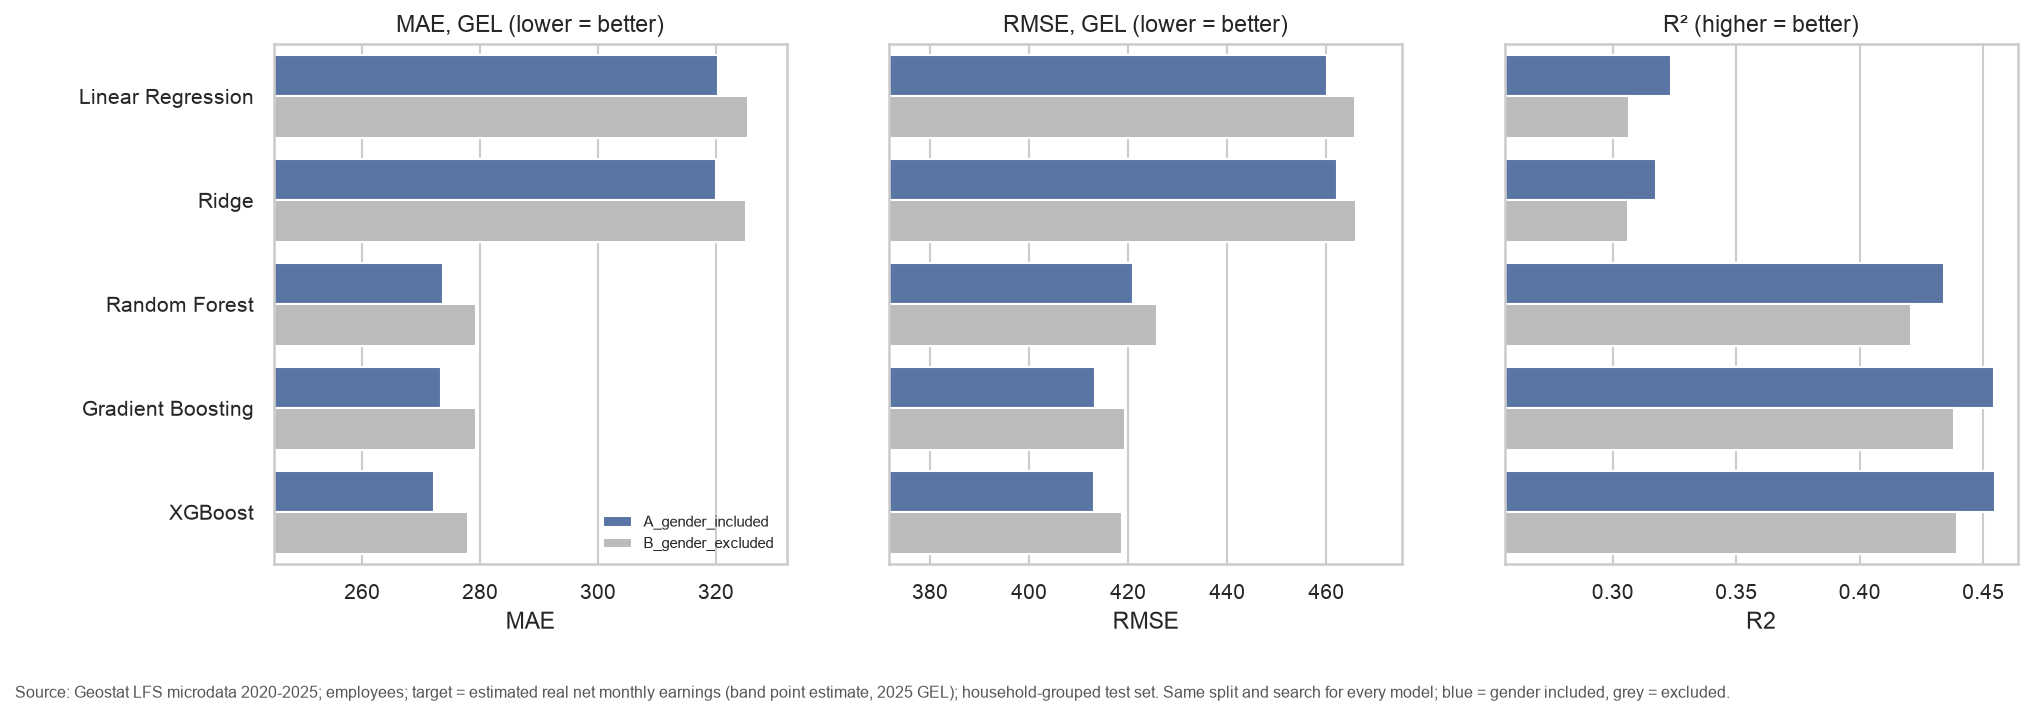

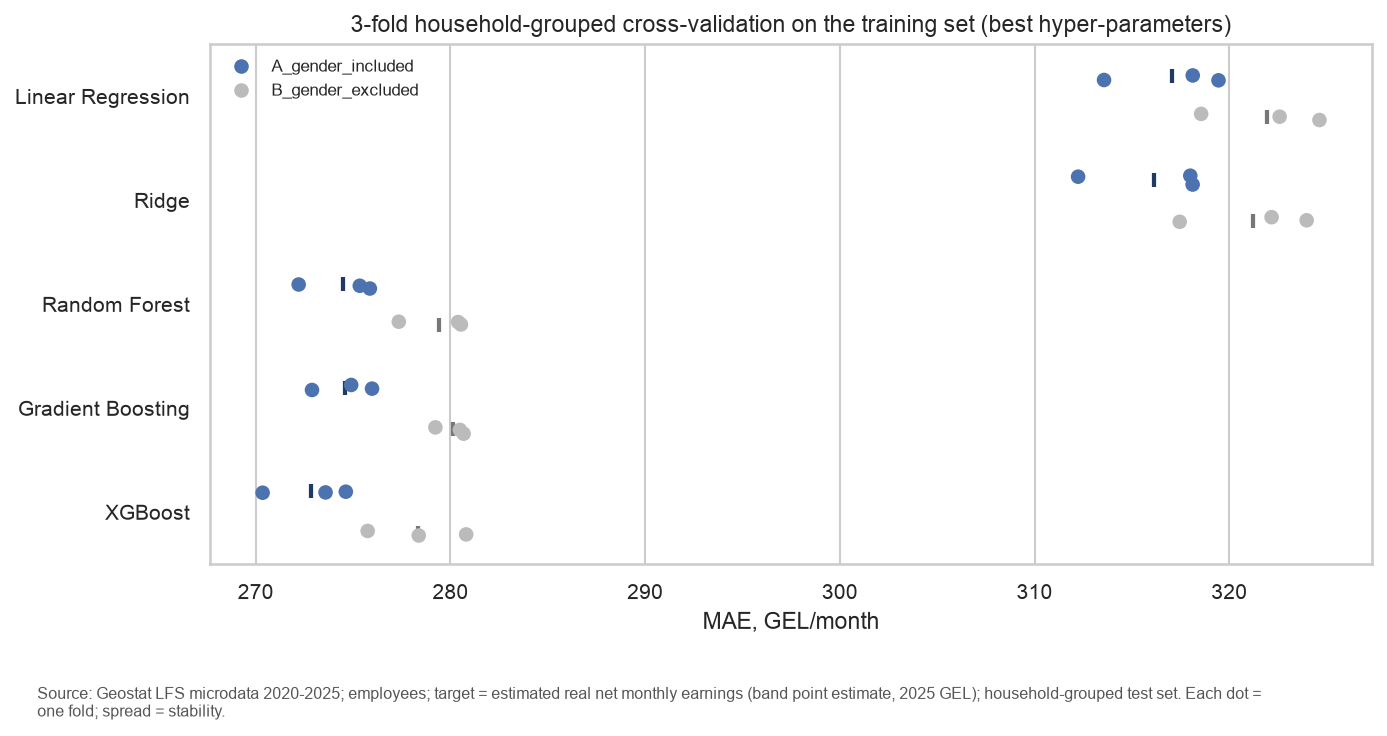

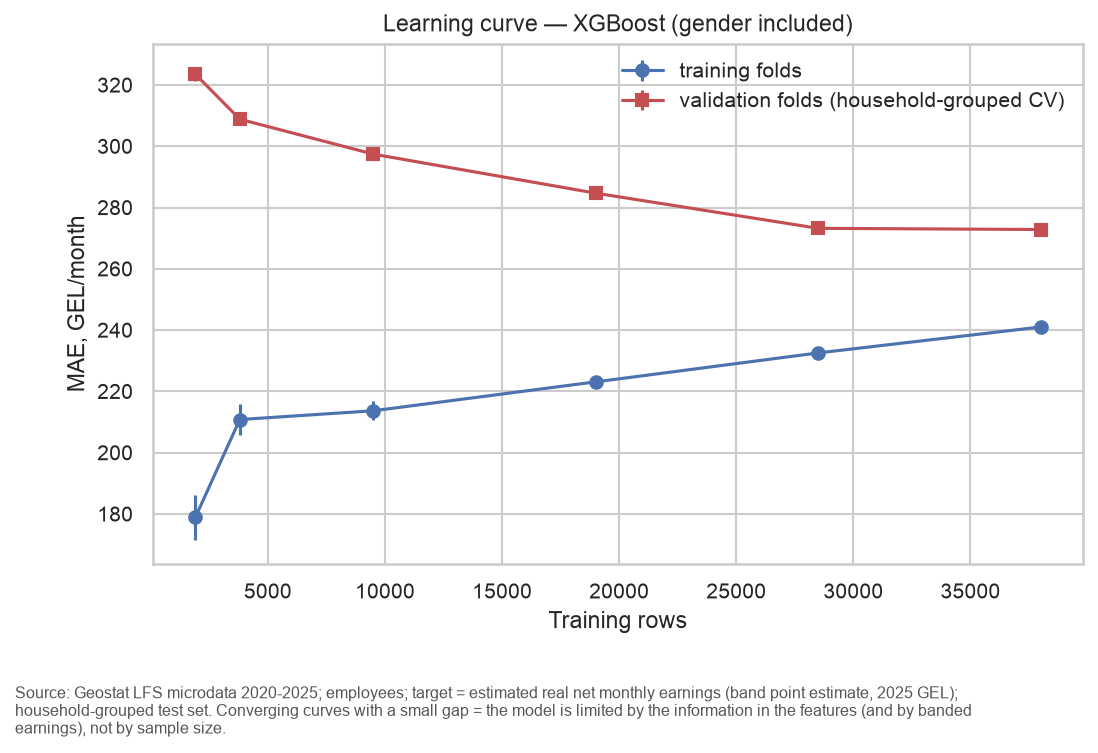

In [5]:
display(Image('../reports/figures/stage_05/03_model_performance_comparison.png'))
display(Image('../reports/figures/stage_05/09_cross_validation_results.png'))
display(Image('../reports/figures/stage_05/08_learning_curve.png'))

In [6]:
display(pd.read_csv(R+'ml_temporal_vs_random.csv'))
display(pd.read_csv(R+'ml_replication_2017_2019.csv'))

,model,experiment,train_years,test_years,n_train,n_test,n,MAE_temporal,MSE,RMSE,R2_temporal,MedAE,R2_log,mean_error,MAE_weighted,MAE_random,R2_random
0,XGBoost,A_gender_included,2020-2023,2024-2025,53181,19824,19824,293.874127,193949.559284,440.397047,0.414125,191.779383,0.553966,-139.684820,306.451735,272.233438,0.454789
1,XGBoost,B_gender_excluded,2020-2023,2024-2025,53181,19824,19824,297.507616,198557.348607,445.597743,0.400206,193.826428,0.543819,-138.391466,311.142012,277.938648,0.439550
2,Linear Regression,A_gender_included,2020-2023,2024-2025,53181,19824,19824,328.046305,219028.457056,468.004762,0.338367,227.248125,0.428006,-76.750128,339.385370,320.428805,0.323367
3,Linear Regression,B_gender_excluded,2020-2023,2024-2025,53181,19824,19824,331.886139,224297.838251,473.600927,0.322450,230.379284,0.419294,-77.055398,343.009006,325.472544,0.306436


,period,model,experiment,n_train,n_test,n,MAE,MSE,RMSE,R2,MedAE,R2_log,mean_error,MAE_weighted
0,2017_2019,XGBoost,A_gender_included,28033,6013,6013,261.895705,188584.973663,434.263714,0.444064,175.928154,0.518214,-28.076540,289.133799
1,2017_2019,XGBoost,B_gender_excluded,28033,6013,6013,264.987370,193373.956933,439.743058,0.429947,179.947574,0.502551,-27.320820,293.971933
2,2017_2019,Linear Regression,A_gender_included,28033,6013,6013,297.978921,228972.412707,478.510619,0.325005,206.696338,0.368865,-6.982738,325.675700
3,2017_2019,Linear Regression,B_gender_excluded,28033,6013,6013,301.317694,233033.440606,482.735373,0.313033,209.267145,0.354630,-6.310333,329.813214


## 3. Best model diagnostics

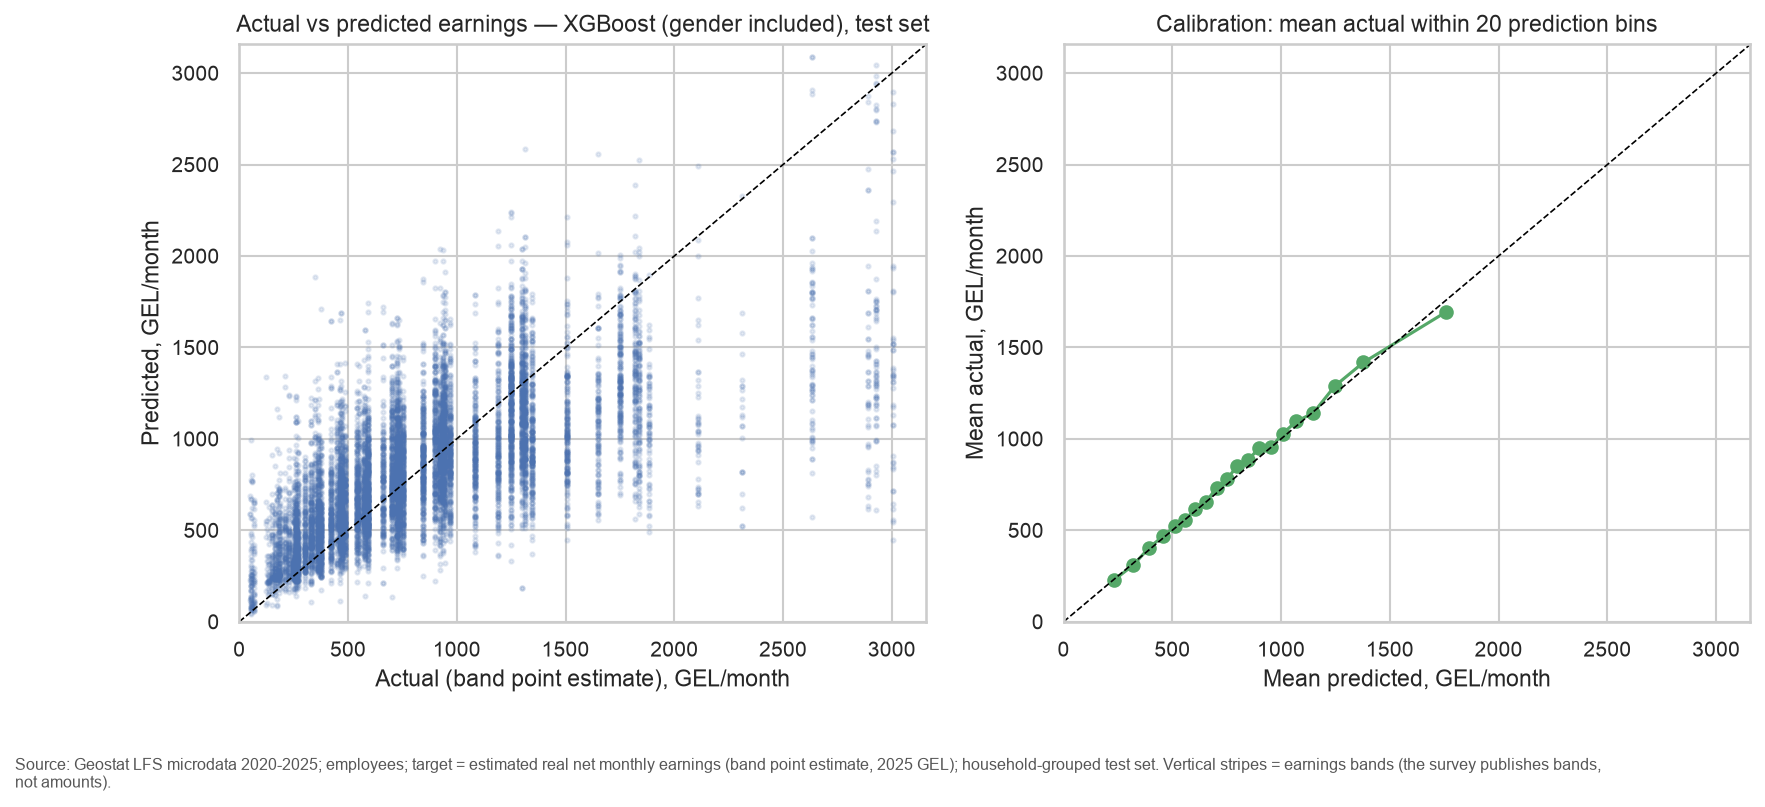

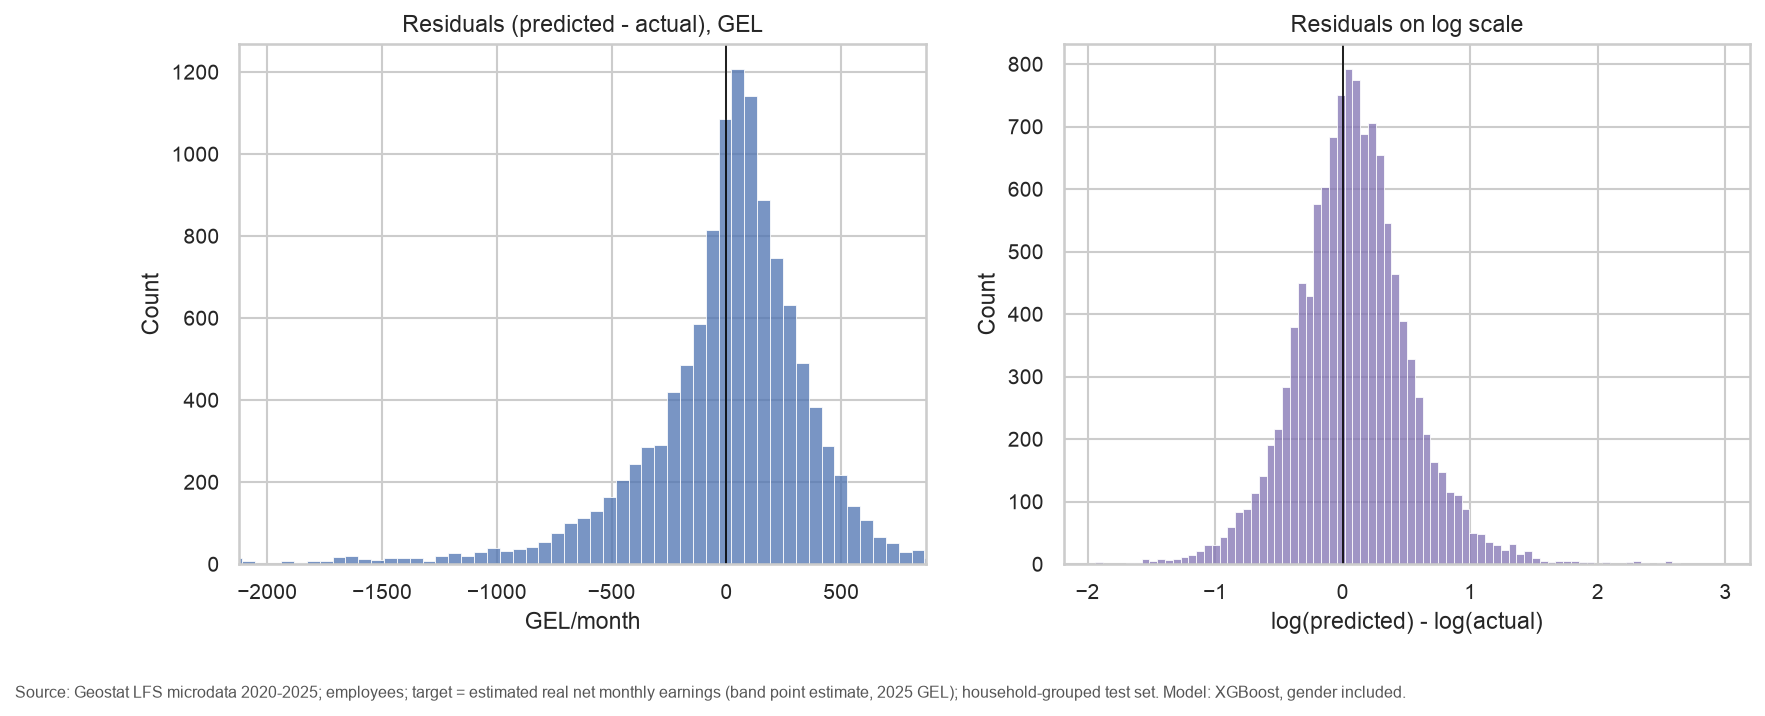

In [7]:
display(Image('../reports/figures/stage_05/01_actual_vs_predicted.png'))
display(Image('../reports/figures/stage_05/02_residual_distribution.png'))

## 4. Gender included vs excluded

In [8]:
display(pd.read_csv(R+'ml_gender_impact.csv'))
display(pd.read_csv(R+'ml_fairness_by_gender.csv'))

,measure,value
0,"actual gap in test set (mean, %)",26.990507
1,"gap in predictions, model A XGBoost (%)",25.010475
2,"gap in predictions, model B XGBoost (%)",17.176484
3,"gender flip: women predicted as men, mean change (%)",17.566095
4,"gender flip: men predicted as women, mean change (%)",-17.399199
5,gender flip: model-implied gap at equal characteristics (%),16.215033
6,proxy check: ROC AUC predicting sex from the other features,0.890329
7,"Stage 04 reference: full regression M7, female coefficie...",-16.685000


,model,experiment,gender,n,mean_actual,mean_predicted,mean_error,MAE,RMSE,MAE_relative_pct,ci_low,ci_high
0,Linear Regression,A_gender_included,female,6147.0,702.376365,719.218786,16.842421,277.002224,393.877056,39.437862,NaN,NaN
1,Linear Regression,A_gender_included,male,5861.0,962.034297,964.957100,2.922802,365.974479,520.682797,38.041729,NaN,NaN
2,Linear Regression,A_gender_included,women - men (MAE diff 95% CI),NaN,NaN,NaN,NaN,-88.972254,NaN,NaN,-108.301851,-67.786570
3,Linear Regression,A_gender_included,women - men (mean error diff 95% CI),NaN,NaN,NaN,13.919619,NaN,NaN,NaN,-12.068866,41.277570
4,Linear Regression,B_gender_excluded,female,6147.0,702.376365,764.717267,62.340902,293.917588,407.449102,41.846167,NaN,NaN
5,Linear Regression,B_gender_excluded,male,5861.0,962.034297,922.543841,-39.490457,358.567292,520.153057,37.271778,NaN,NaN
6,Linear Regression,B_gender_excluded,women - men (MAE diff 95% CI),NaN,NaN,NaN,NaN,-64.649704,NaN,NaN,-83.400617,-43.000323
7,Linear Regression,B_gender_excluded,women - men (mean error diff 95% CI),NaN,NaN,NaN,101.831359,NaN,NaN,NaN,74.206398,130.345168
8,Ridge,A_gender_included,female,6147.0,702.376365,712.059590,9.683225,277.564146,396.260082,39.517865,NaN,NaN
9,Ridge,A_gender_included,male,5861.0,962.034297,944.527252,-17.507045,364.398411,522.373408,37.877902,NaN,NaN


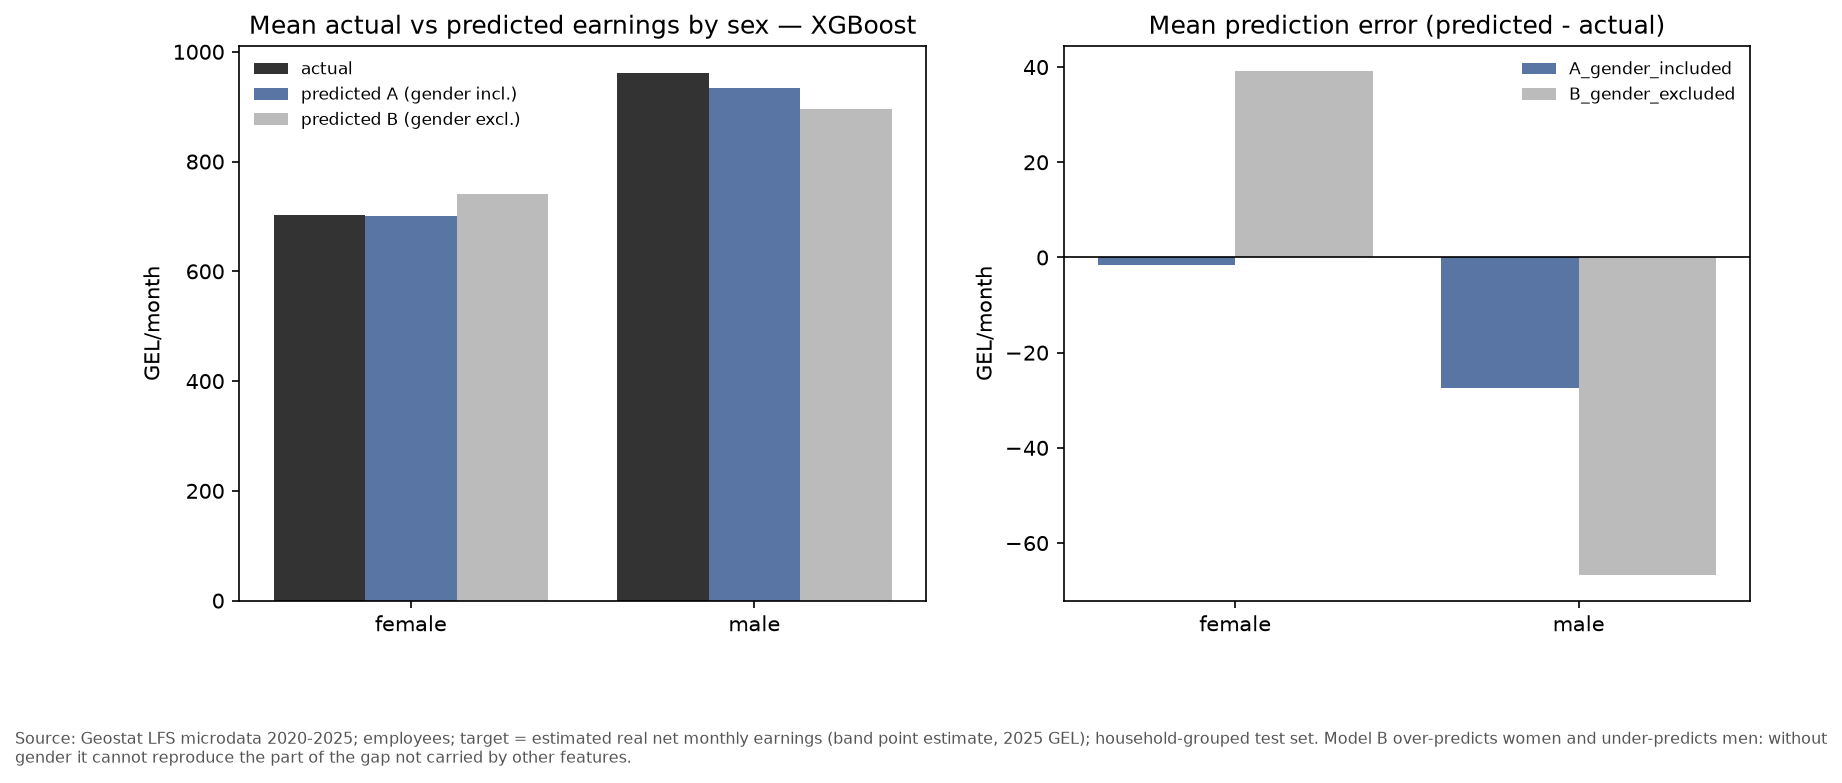

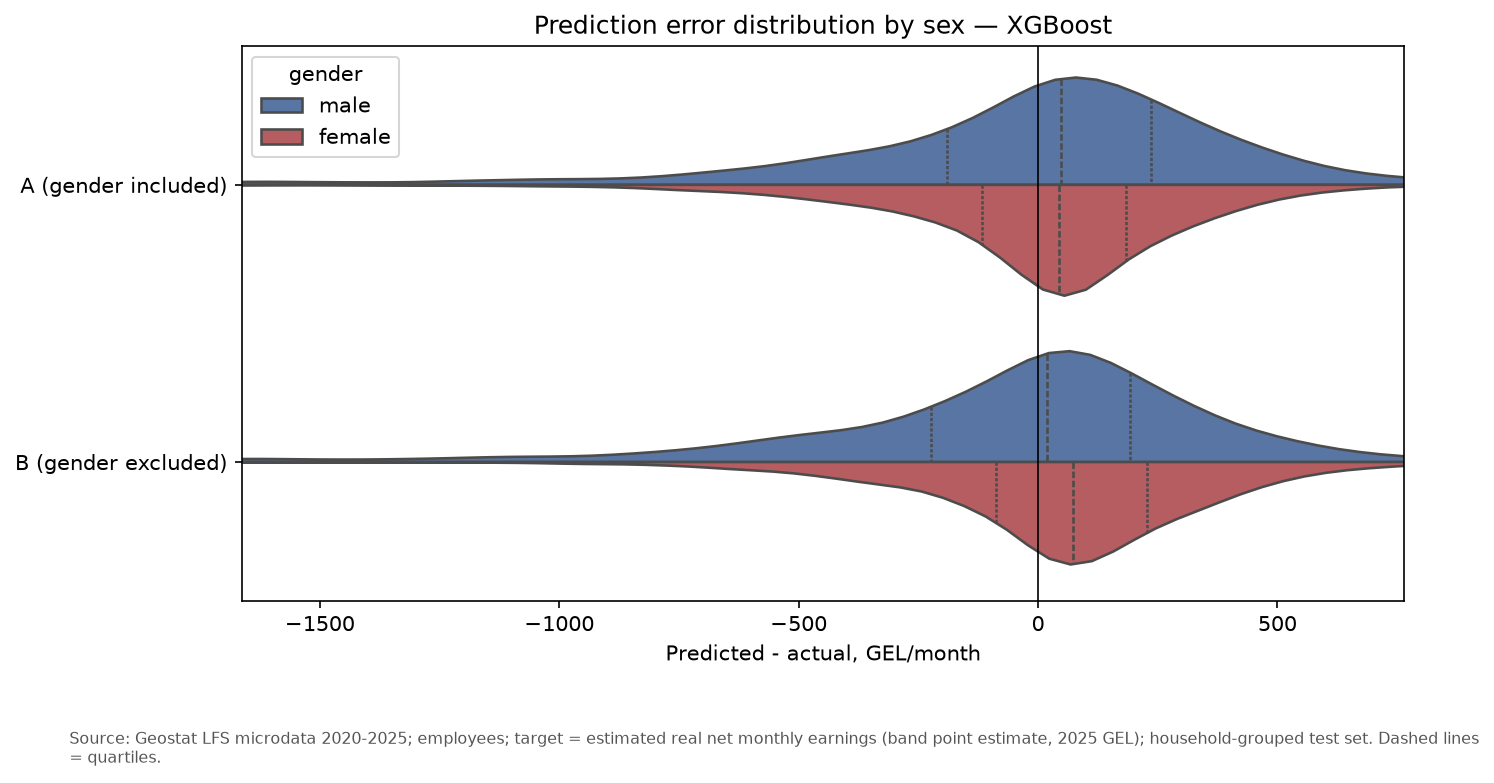

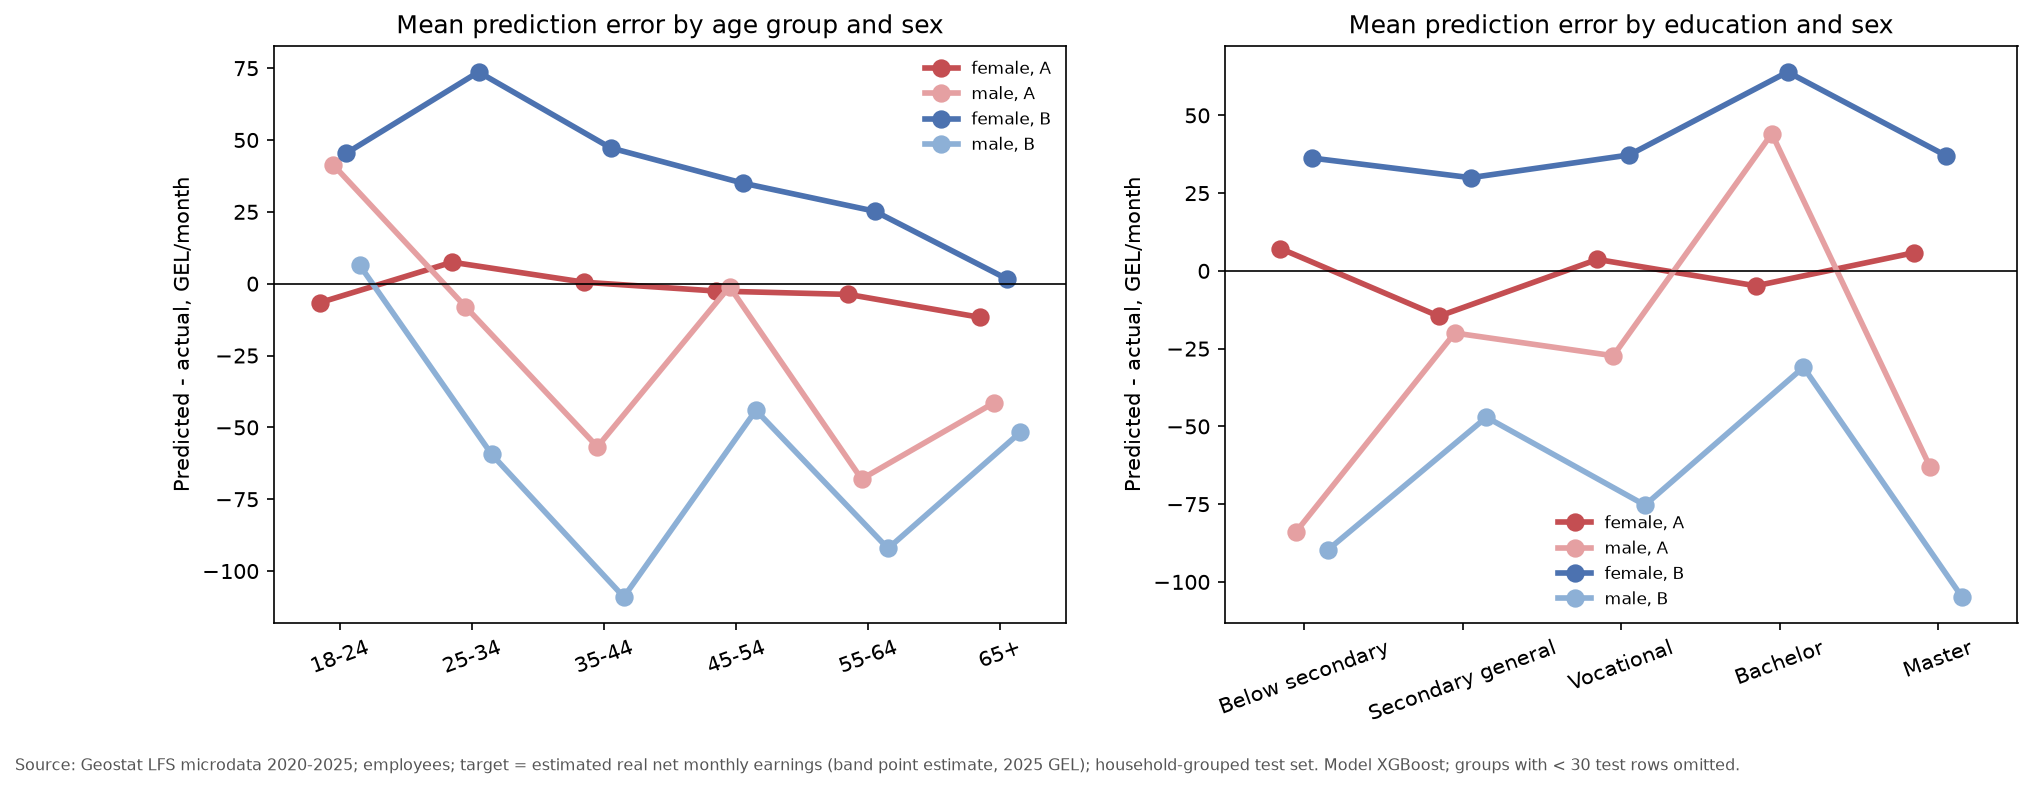

In [9]:
display(Image('../reports/figures/stage_05/06_gender_prediction_comparison.png'))
display(Image('../reports/figures/stage_05/07_error_distribution_by_gender.png'))
display(Image('../reports/figures/stage_05/11_fairness_by_age_education.png'))

## 5. Feature importance and SHAP

In [10]:
display(pd.read_csv(R+'ml_permutation_importance.csv'))
display(pd.read_csv(R+'ml_shap_importance.csv'))
display(pd.read_csv(R+'ml_shap_gender.csv'))

,experiment,feature,mae_increase_gel,sd
0,A_gender_included,industry,59.229949,1.131593
1,A_gender_included,occupation,52.135692,0.851802
2,A_gender_included,survey_year,24.569642,0.806818
3,A_gender_included,working_hours,23.573587,0.594991
4,A_gender_included,gender,21.648921,0.737286
5,A_gender_included,education,18.437912,0.640890
6,A_gender_included,region,14.765890,0.470016
7,A_gender_included,sector,13.667596,1.203280
8,A_gender_included,informality,13.094668,1.284531
9,A_gender_included,potential_experience,3.738736,0.422790


,feature,mean_abs_shap_log,approx_pct_effect
0,occupation,0.158639,17.191483
1,industry,0.138410,14.844584
2,survey_year,0.107685,11.369694
3,gender,0.091240,9.553230
4,education,0.090927,9.518933
5,working_hours,0.074316,7.714736
6,region,0.070474,7.301712
7,sector,0.061933,6.389117
8,informality,0.050647,5.195177
9,potential_experience,0.041369,4.223704


,gender,mean,std,count,pct
0,female,-0.088226,0.030728,1508,-8.444601
1,male,0.093737,0.031130,1492,9.827137


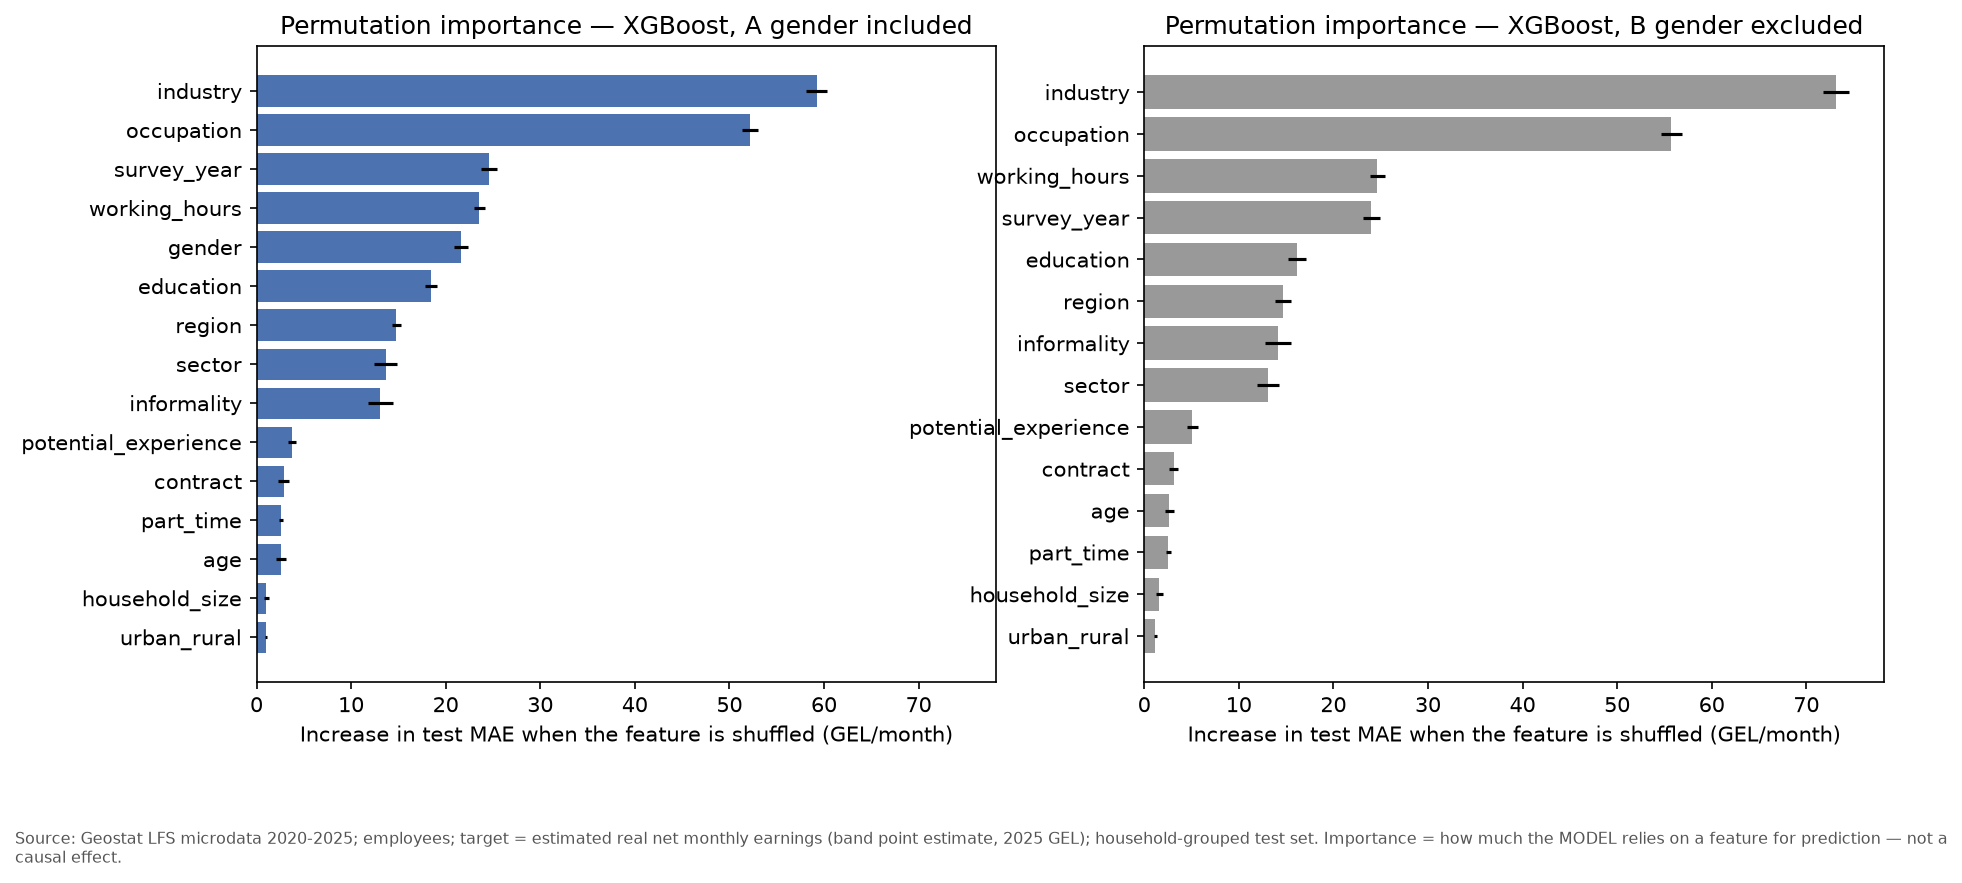

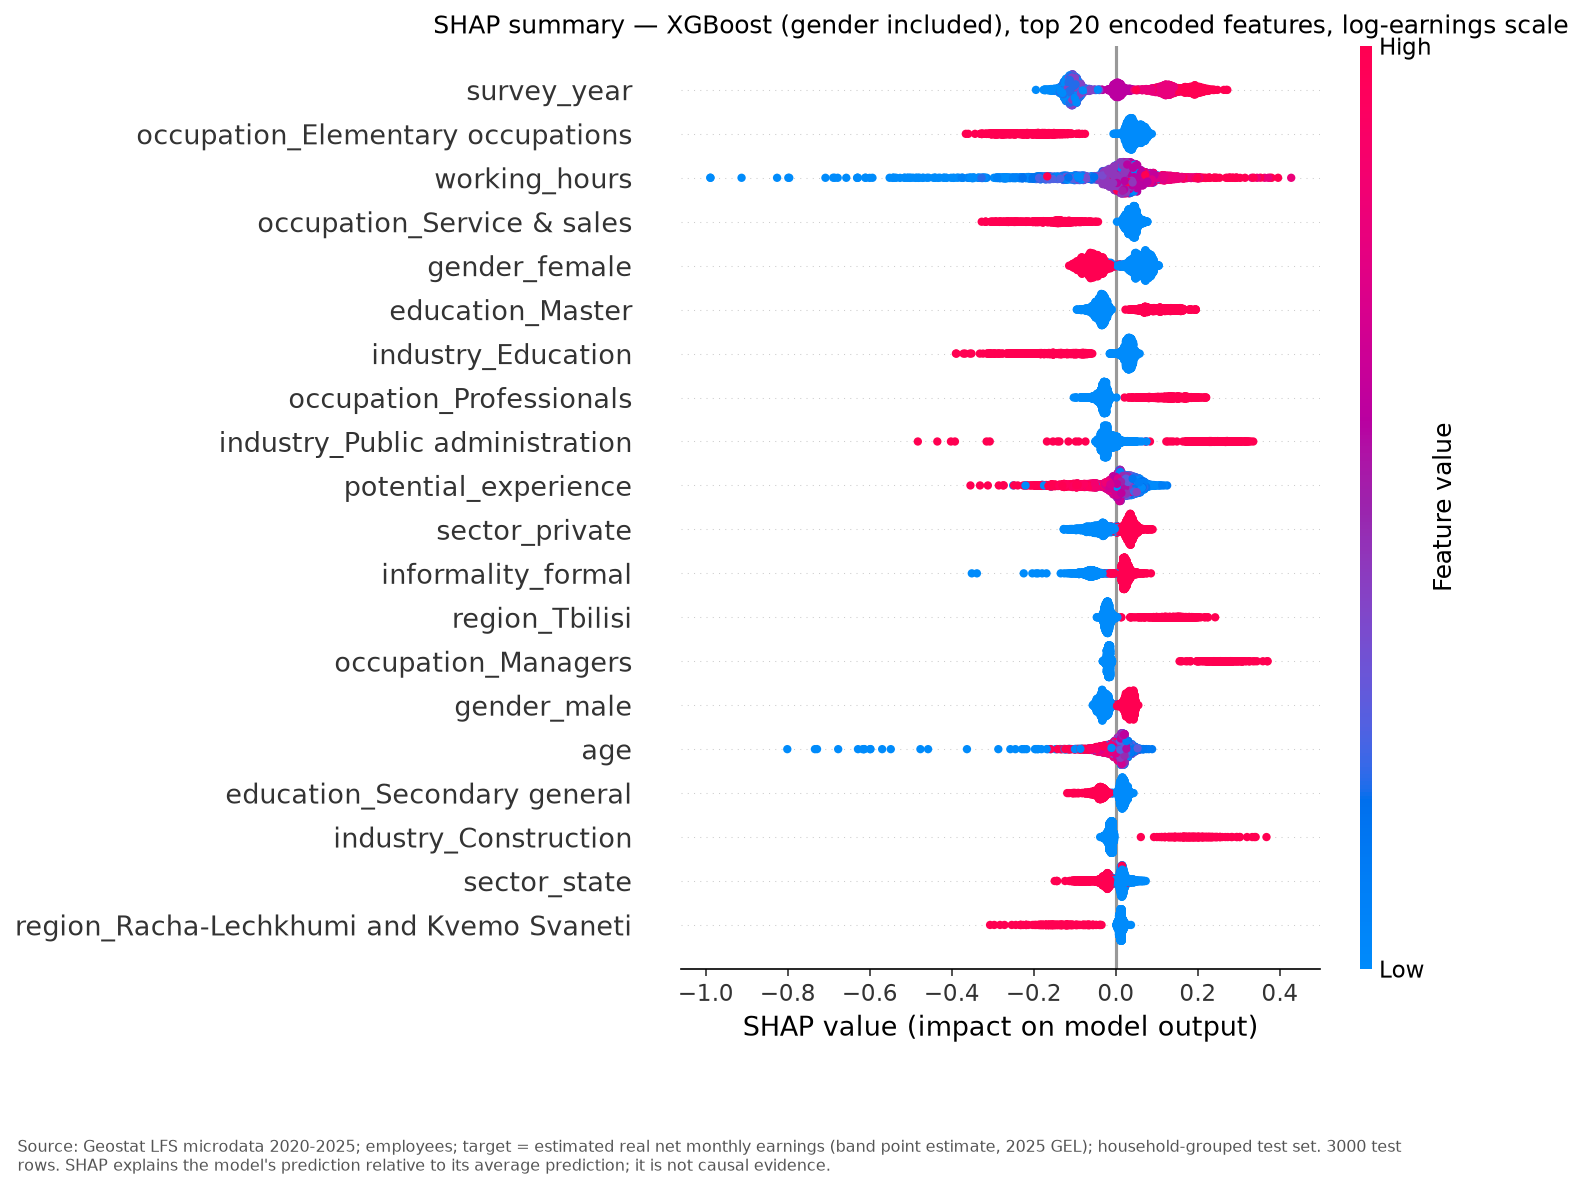

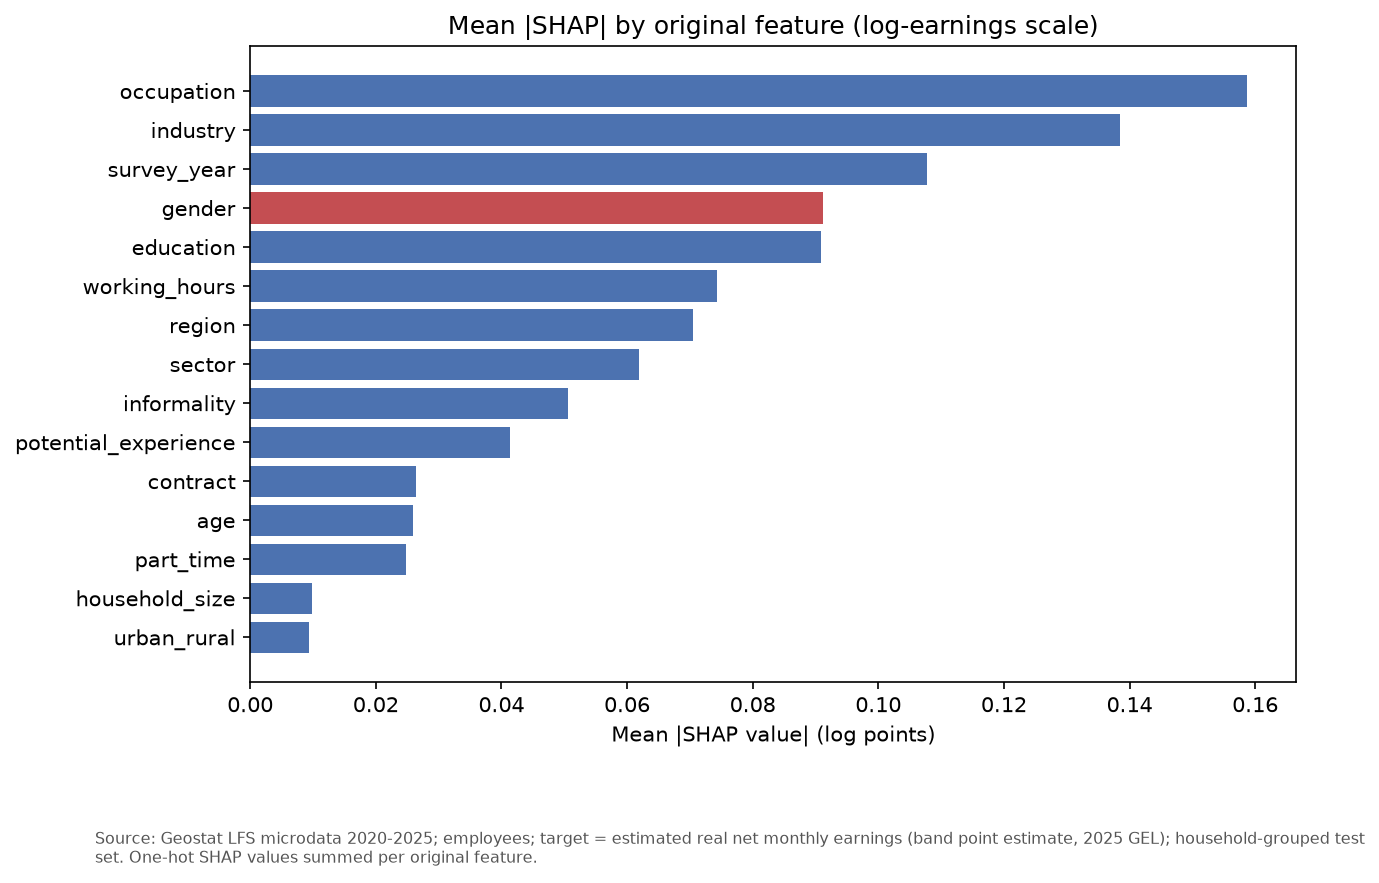

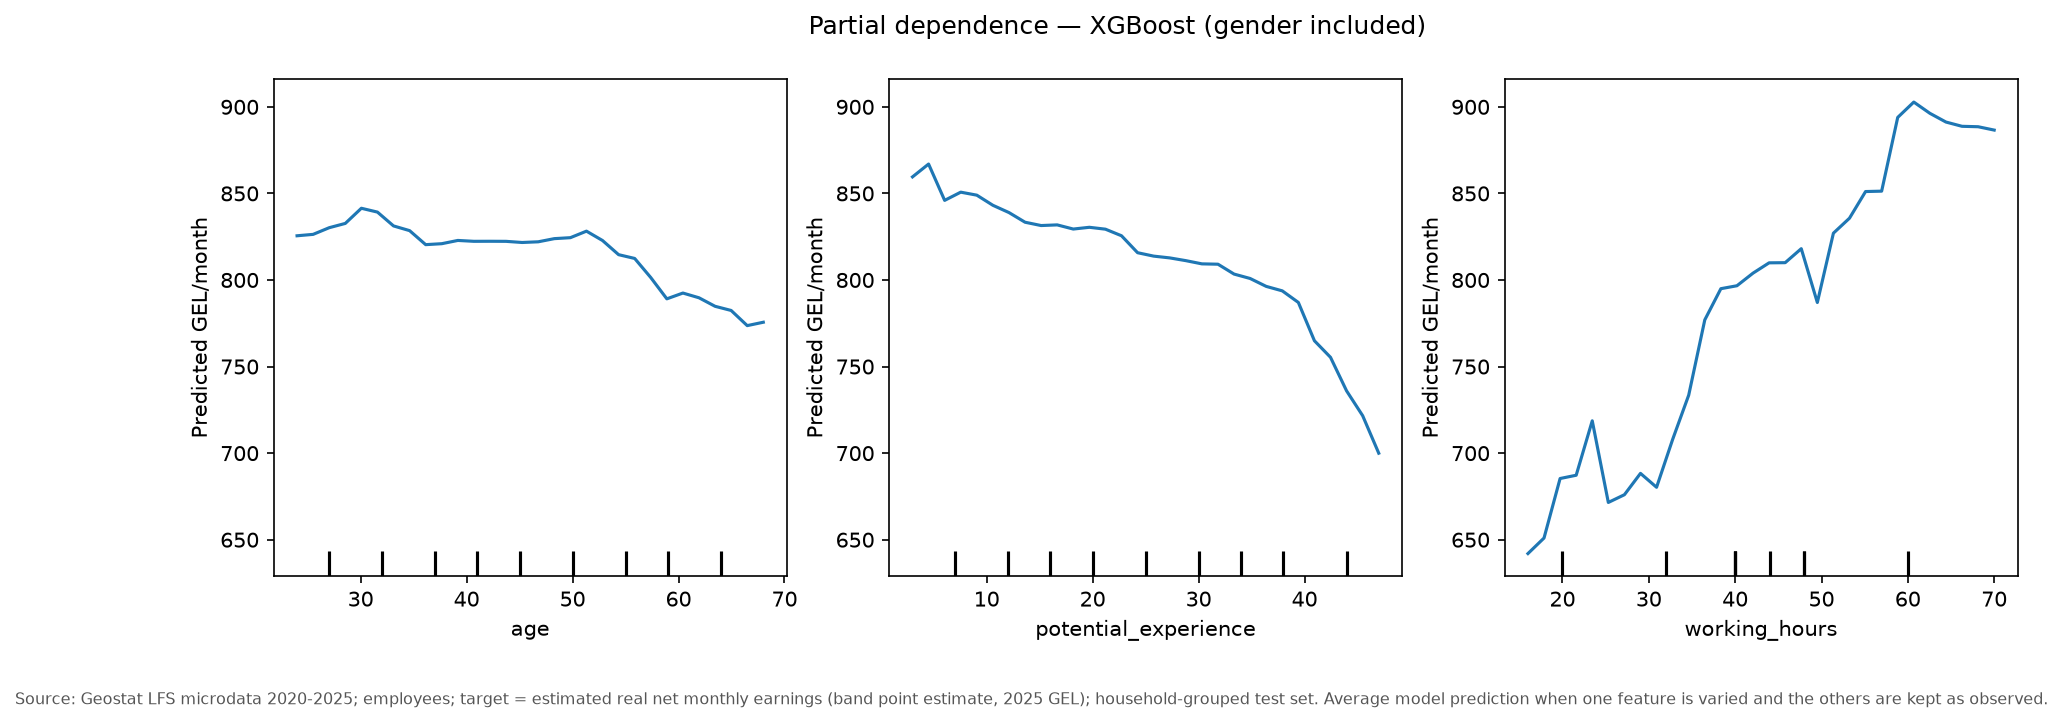

In [11]:
display(Image('../reports/figures/stage_05/04_feature_importance.png'))
display(Image('../reports/figures/stage_05/05_shap_summary.png'))
display(Image('../reports/figures/stage_05/05b_shap_by_feature.png'))
display(Image('../reports/figures/stage_05/05c_partial_dependence.png'))

## 6. Saved model: reload and re-check; prediction script (fictional profiles)

In [12]:
m = joblib.load('../models/best_income_model.joblib')
te = df[part.to_numpy()=='test']
print(me.metrics(te[pp.TARGET], m.predict(te[pp.FEATURES_A])))
pi.predict(pd.DataFrame(pi.DEMO))[['gender','age','education','occupation','predicted_net_monthly_earnings_gel_2025']]

{'n': 12008, 'MAE': 272.23343756235187, 'MSE': 170616.71152879889, 'RMSE': 413.057758102664, 'R2': 0.4547893936324072, 'MedAE': 185.74930962132288, 'R2_log': 0.550029600683196, 'mean_error': -14.147558541739185}


,gender,age,education,occupation,predicted_net_monthly_earnings_gel_2025
0,female,34,Master,Professionals,1012.200012
1,male,34,Master,Professionals,1134.599976
2,female,52,Vocational,Service & sales,548.000000
